In [1]:
%pip install opencv-python


Note: you may need to restart the kernel to use updated packages.


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

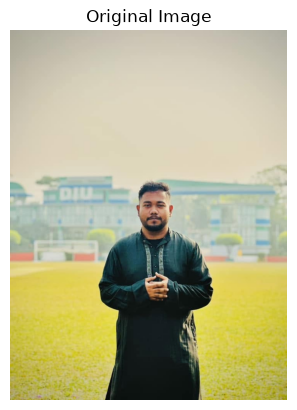

Image Shape: (960, 720, 3)


In [3]:
image_path ="/Users/jayanto/Desktop/482056713_1169471237860557_1984739834276924522_n.jpg"
img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

print("Image Shape:", img.shape)

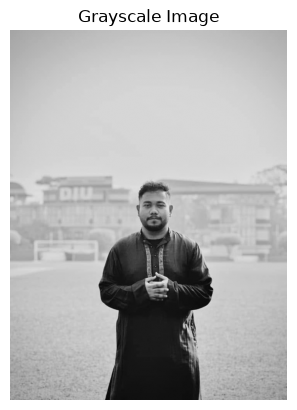

Gray Shape: (960, 720)


In [4]:
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

plt.imshow(gray, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

print("Gray Shape:", gray.shape)

In [5]:
kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

print(kernel)

[[-1 -1 -1]
 [-1  8 -1]
 [-1 -1 -1]]


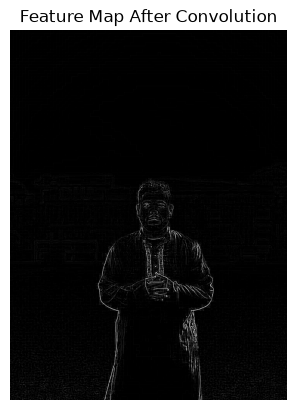

Feature Map Shape: (960, 720)


In [6]:
feature_map = cv2.filter2D(gray, -1, kernel)

plt.imshow(feature_map, cmap='gray')
plt.title("Feature Map After Convolution")
plt.axis("off")
plt.show()

print("Feature Map Shape:", feature_map.shape)

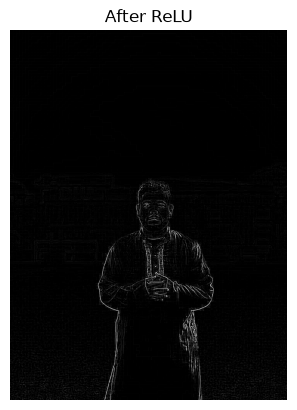

 Shape: (960, 720)


In [7]:
relu_output = np.maximum(0, feature_map)

plt.imshow(relu_output, cmap='gray')
plt.title("After ReLU")
plt.axis("off")
plt.show()
print(" Shape:", relu_output.shape)

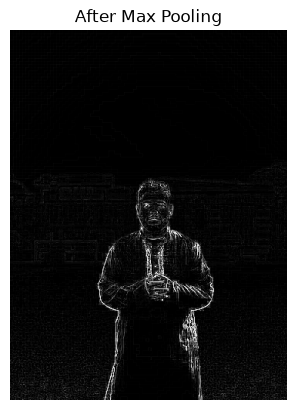

Pooled Shape: (480, 360)


In [8]:
pool_size = 2

h, w = relu_output.shape

pooled = np.zeros((h//2, w//2))

for i in range(0, h-1, 2):
    for j in range(0, w-1, 2):
        pooled[i//2, j//2] = np.max(
            relu_output[i:i+2, j:j+2]
        )

plt.imshow(pooled, cmap='gray')
plt.title("After Max Pooling")
plt.axis("off")
plt.show()

print("Pooled Shape:", pooled.shape)

In [9]:
print("Original :", img.shape)
print("Gray     :", gray.shape)
print("Conv     :", feature_map.shape)
print("ReLU     :", relu_output.shape)
print("Pooling  :", pooled.shape)

Original : (960, 720, 3)
Gray     : (960, 720)
Conv     : (960, 720)
ReLU     : (960, 720)
Pooling  : (480, 360)


In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D

model = Sequential()

model.add(
    Conv2D(
        filters=32,
        kernel_size=(3,3),
        activation='relu',
        input_shape=(224,224,3)
    )
)

model.add(MaxPooling2D(pool_size=(2,2)))

model.summary()

/opt/anaconda3/envs/tensorflow312/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 896 (3.50 KB)

 Trainable params: 896 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Resize image to match model input
img_resized = cv2.resize(img, (224,224))
img_resized = img_resized / 255.0

# Add batch dimension
input_img = np.expand_dims(img_resized, axis=0)

print("Input shape for CNN:", input_img.shape)

Input shape for CNN: (1, 224, 224, 3)


In [12]:
output = model.predict(input_img)

print("Output shape:", output.shape)
print(output)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
Output shape: (1, 111, 111, 32)
[[[[0.08186324 0.06021018 0.06503455 ... 0.16389044 0.07169226
    0.        ]
   [0.08269966 0.0597419  0.0648374  ... 0.1654752  0.07186674
    0.        ]
   [0.08431677 0.06277759 0.06598891 ... 0.16754143 0.07268357
    0.        ]
   ...
   [0.08728868 0.06066252 0.06436908 ... 0.17814435 0.08207776
    0.        ]
   [0.08652177 0.06014456 0.06263778 ... 0.17989479 0.08280645
    0.        ]
   [0.08712465 0.05980153 0.06296018 ... 0.179447   0.0828905
    0.        ]]

  [[0.0824426  0.06113429 0.06458846 ... 0.16679697 0.07155023
    0.        ]
   [0.08332178 0.06312046 0.06620146 ... 0.16667059 0.07151982
    0.        ]
   [0.08478311 0.06481364 0.06900151 ... 0.16872852 0.06995411
    0.        ]
   ...
   [0.08775529 0.0599921  0.06657673 ... 0.18076122 0.08335336
    0.        ]
   [0.08775899 0.06164734 0.06391659 ... 0.1791344  0.08393949
    0.        ]
   [0.08684942 0.06065388 0.06258222 ... 0.178

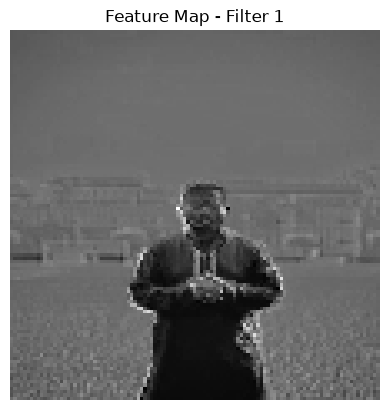

In [13]:
plt.imshow(output[0, :, :, 0], cmap='gray')
plt.title("Feature Map - Filter 1")
plt.axis("off")
plt.show()

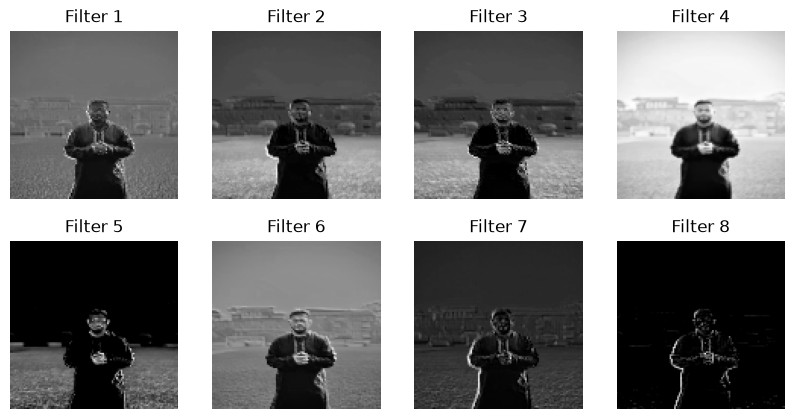

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(10,5))

for i in range(8):
    ax = axes[i//4, i%4]
    ax.imshow(output[0, :, :, i], cmap='gray')
    ax.axis("off")
    ax.set_title(f"Filter {i+1}")

plt.show()